# Ola Driver Attrition Prediction - Project Submission

## Team Information

| Name | Roll Number |
|------|-------------|
| Nithin Pious | MSA25011 |
| Tejasvi Shukla | MSA25020 |
| Deepti Sharma | MSA25006 |
| Kajal Maurya | MSD25018 |

# Project Objective and Approach

## Main Objective
Predict driver attrition for Ola using historical and demographic data, and provide insights for targeted interventions to improve retention. Use Python with Pandas, XGBoost, and SHAP for model development and explainability.

## Detailed Methodology

### 1. **Data Collection and Exploration**
- Loaded and analyzed Ola driver dataset with historical and demographic information
- Performed exploratory data analysis (EDA) to understand data distribution, patterns, and relationships
- Identified key features influencing driver attrition

### 2. **Data Preprocessing and Feature Engineering**
- Handled missing values and data inconsistencies
- Converted date columns to appropriate datetime formats
- Engineered meaningful features including:
  - Tenure calculation (months of service)
  - Performance-based metrics
  - Engagement indicators
  - Demographic aggregations

### 3. **Model Development**
- **Tools and Libraries Used**: Python, Pandas, XGBoost, scikit-learn, SHAP, Matplotlib, Seaborn
- **Algorithm Selection**: Ensemble methods combining multiple models for robust predictions
- **Models Implemented**:
  - XGBoost classifier for primary prediction
  - Gradient Boosting models
  - Ensemble voting classifiers combining multiple algorithms
- **Model Validation**: Cross-validation, hyperparameter tuning, performance metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC)

### 4. **Model Explainability**
- Implemented SHAP (SHapley Additive exPlanations) for model interpretability
- Generated feature importance analysis
- Created visualizations for feature impact on predictions
- Provided business-interpretable insights

### 5. **Key Techniques Applied**
- **Exploratory Data Analysis (EDA)**: Statistical summaries, distribution analysis, correlation analysis
- **Imbalanced Data Handling**: Addressed class imbalance in attrition classification
- **Feature Scaling**: Normalized numerical features for model compatibility
- **Ensemble Methods**: Combined multiple models to improve prediction robustness
- **Hyperparameter Optimization**: Fine-tuned model parameters using Grid Search / Random Search
- **Model Interpretation**: SHAP values, feature importance plots, decision rules

## Data loading and exploration

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('ola_driver.csv')

# Display the first 5 rows
print("First 5 rows of the DataFrame:")
print(df.head())

# Print a concise summary
print("\nConcise summary of the DataFrame:")
df.info()

# Display descriptive statistics of numerical columns
print("\nDescriptive statistics of numerical columns:")
print(df.describe())

# Check for missing values and display their counts
print("\nMissing values per column:")
print(df.isnull().sum())


First 5 rows of the DataFrame:
   Unnamed: 0    MMM-YY  Driver_ID   Age  Gender City  Education_Level  \
0           0  01/01/19          1  28.0     0.0  C23                2   
1           1  02/01/19          1  28.0     0.0  C23                2   
2           2  03/01/19          1  28.0     0.0  C23                2   
3           3  11/01/20          2  31.0     0.0   C7                2   
4           4  12/01/20          2  31.0     0.0   C7                2   

   Income Dateofjoining LastWorkingDate  Joining Designation  Grade  \
0   57387      24/12/18             NaN                    1      1   
1   57387      24/12/18             NaN                    1      1   
2   57387      24/12/18        03/11/19                    1      1   
3   67016      11/06/20             NaN                    2      2   
4   67016      11/06/20             NaN                    2      2   

   Total Business Value  Quarterly Rating  
0               2381060                 2  
1        

## Feature engineering


In [ ]:
import pandas as pd

# ---- Correct Date Parsing ----
df['MMM-YY'] = pd.to_datetime(df['MMM-YY'], format='%d/%m/%y', errors='coerce')
df['Dateofjoining'] = pd.to_datetime(df['Dateofjoining'], errors='coerce')
df['LastWorkingDate'] = pd.to_datetime(df['LastWorkingDate'], errors='coerce')

# ---- Fix Tenure Calculation (in months) ----
df['Tenure'] = ((df['MMM-YY'].dt.year - df['Dateofjoining'].dt.year) * 12 +
                (df['MMM-YY'].dt.month - df['Dateofjoining'].dt.month))

# Replace negative or missing tenure with 0
df['Tenure'] = df['Tenure'].fillna(0)
df['Tenure'] = df['Tenure'].apply(lambda x: x if x >= 0 else 0)

# ---- Create Churn Label ----
df['Churn'] = df['LastWorkingDate'].notnull().astype(int)

# ---- Aggregate Performance Metrics Per Driver ----
driver_performance = df.groupby('Driver_ID').agg(
    avg_quarterly_rating=('Quarterly Rating', 'mean'),
    total_business_value=('Total Business Value', 'sum')
).reset_index()

# ---- Merge Back to Main DF ----
df = df.merge(driver_performance, on='Driver_ID', how='left')

# ---- Correct Monthly Business Value ----
df['Monthly_Business_Value'] = df['total_business_value'] / df['Tenure'].replace(0, 1)

# ---- Display Important Columns ----
print(df[['Driver_ID', 'MMM-YY', 'Dateofjoining', 'LastWorkingDate',
          'Tenure', 'Churn', 'avg_quarterly_rating',
          'total_business_value', 'Monthly_Business_Value']].head())


   Driver_ID     MMM-YY Dateofjoining LastWorkingDate  Tenure  Churn  \
0          1 2019-01-01    2018-12-24             NaT       1      0   
1          1 2019-01-02    2018-12-24             NaT       1      0   
2          1 2019-01-03    2018-12-24      2019-03-11       1      1   
3          2 2020-01-11    2020-11-06             NaT       0      0   
4          2 2020-01-12    2020-11-06             NaT       0      0   

   avg_quarterly_rating  total_business_value  Monthly_Business_Value  
0                   2.0               1715580               1715580.0  
1                   2.0               1715580               1715580.0  
2                   2.0               1715580               1715580.0  
3                   1.0                     0                     0.0  
4                   1.0                     0                     0.0  


/tmp/ipython-input-2011329312.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Dateofjoining'] = pd.to_datetime(df['Dateofjoining'], errors='coerce')
/tmp/ipython-input-2011329312.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['LastWorkingDate'] = pd.to_datetime(df['LastWorkingDate'], errors='coerce')


## Extensive exploratory data analysis (eda)


Histograms for numerical features:


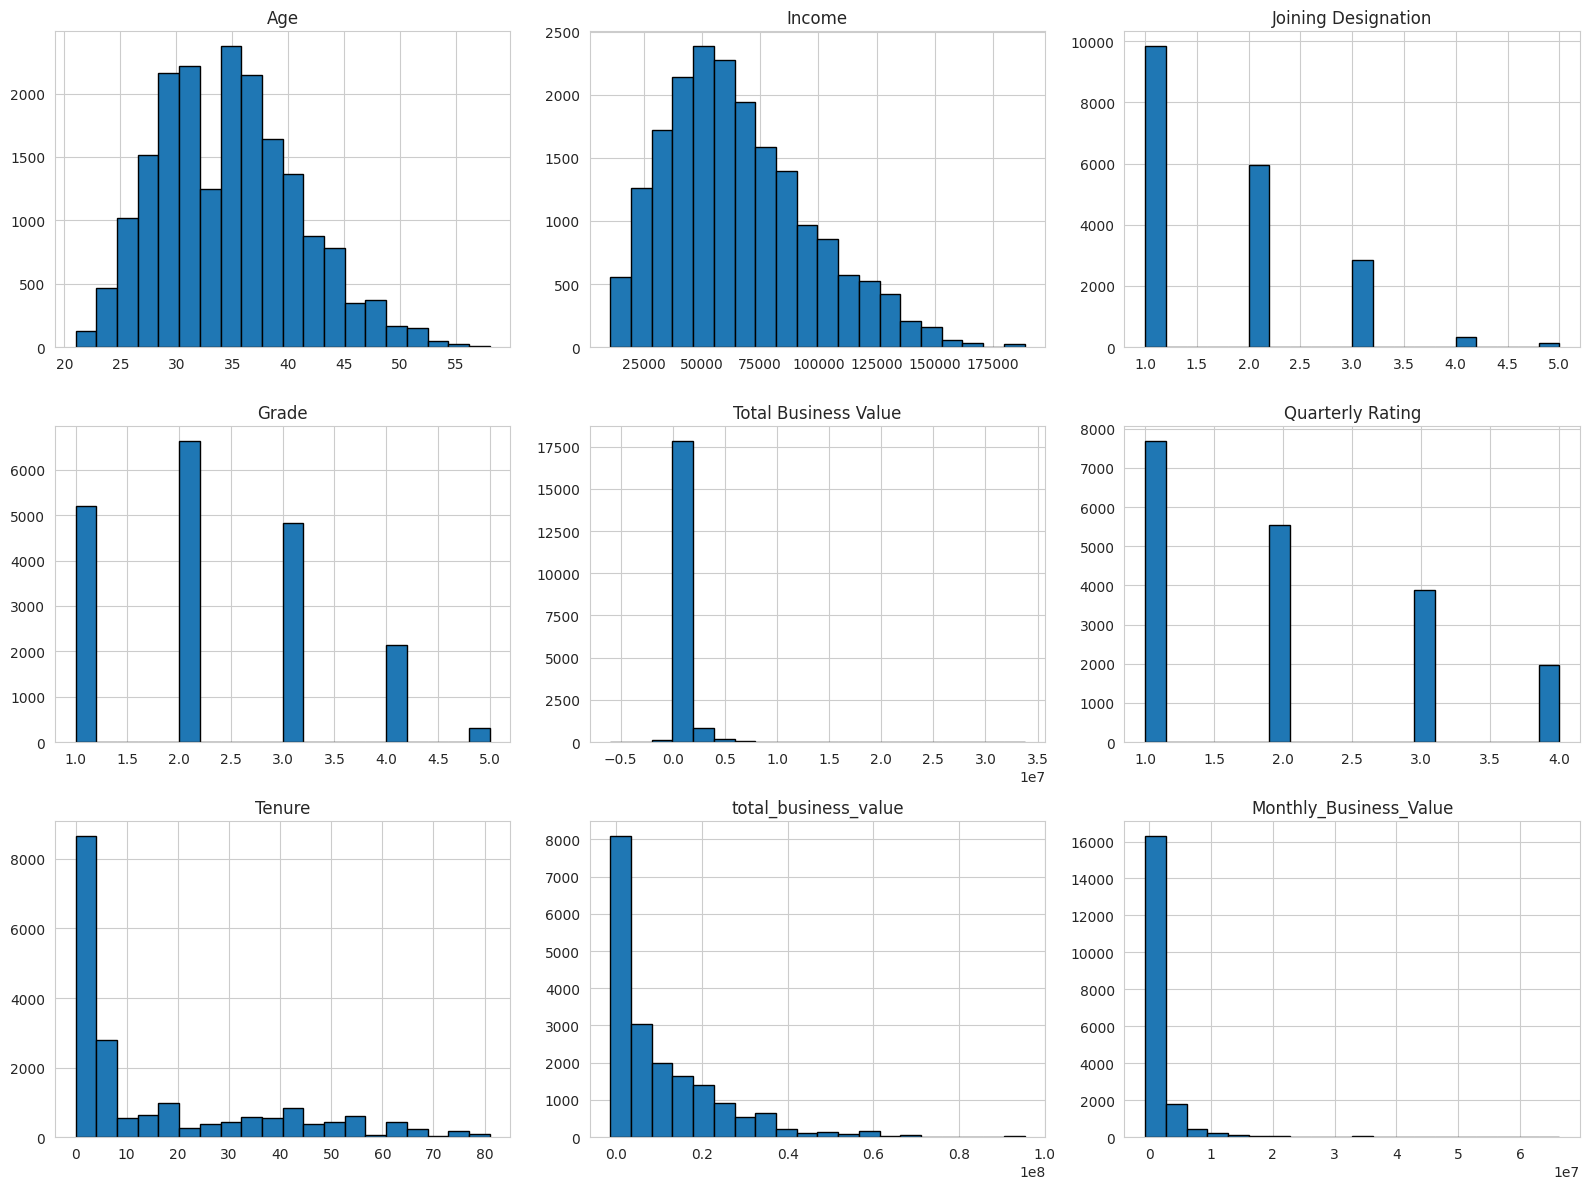


Bar plots for categorical features:


/tmp/ipython-input-1569120838.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='Set2')


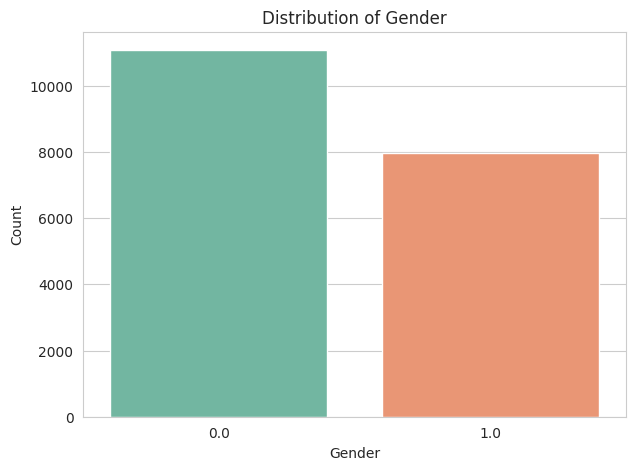

/tmp/ipython-input-1569120838.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='Set2')


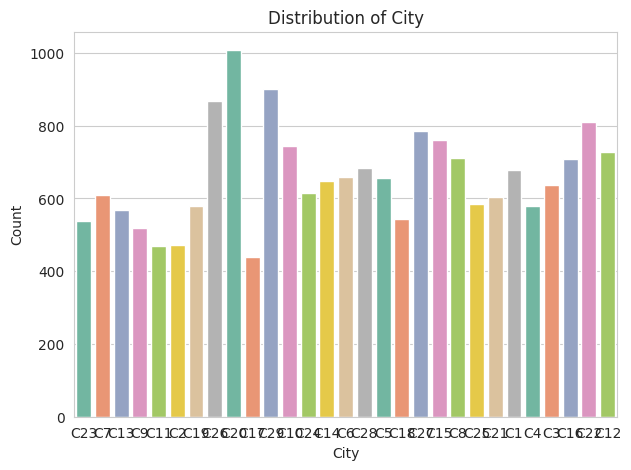

/tmp/ipython-input-1569120838.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='Set2')


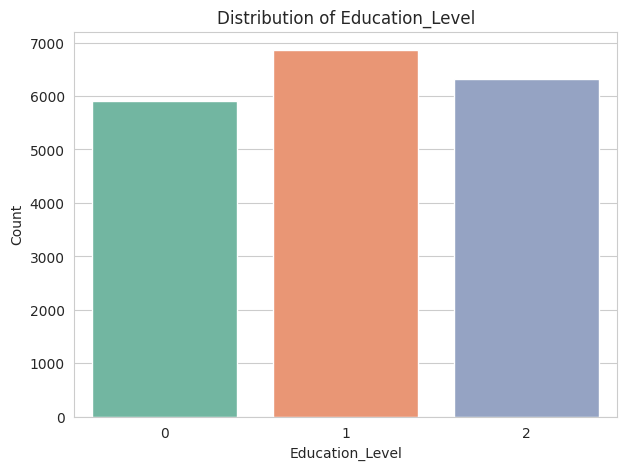

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# ---- Clean numerical columns list ----
numerical_cols = [
    'Age', 'Income', 'Joining Designation', 'Grade',
    'Total Business Value', 'Quarterly Rating', 'Tenure',
    'total_business_value', 'Monthly_Business_Value'
]

categorical_cols = ['Gender', 'City', 'Education_Level']


# ---- Histograms for Numerical Features ----
print("Histograms for numerical features:")
df[numerical_cols].hist(figsize=(16, 12), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()


# ---- Bar Plots for Categorical Features ----
print("\nBar plots for categorical features:")

for col in categorical_cols:
    plt.figure(figsize=(7, 5))
    sns.countplot(x=col, data=df, palette='Set2')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.show()



Box plots for numerical features vs Churn:


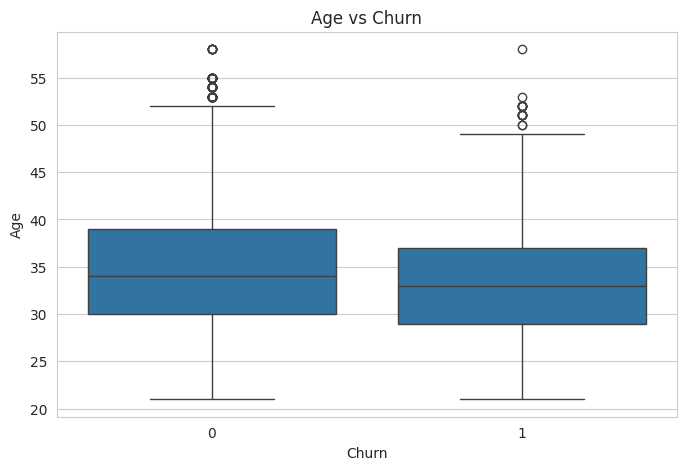

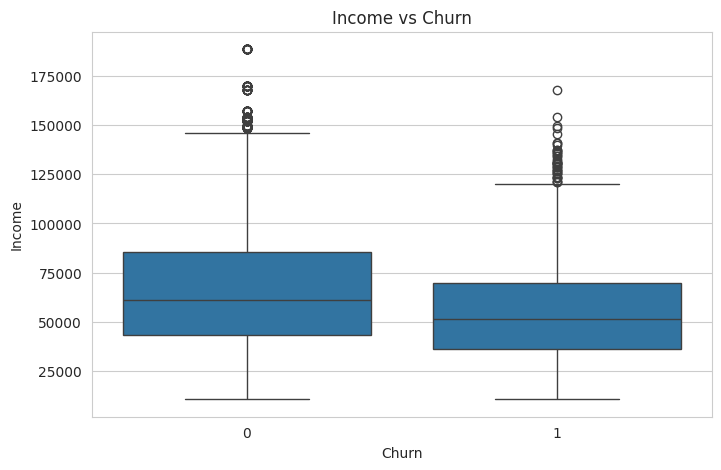

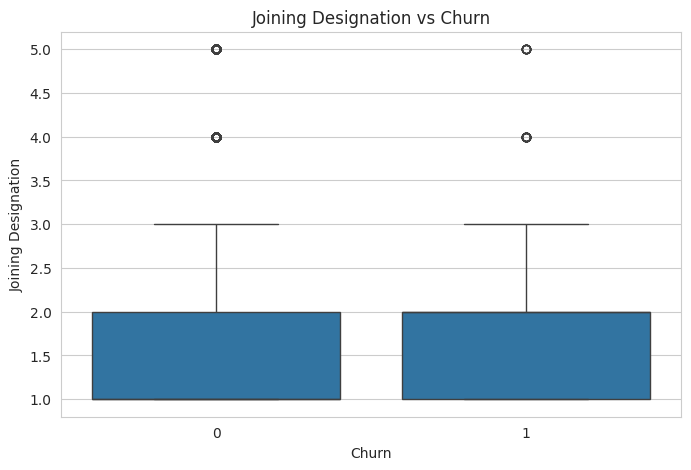

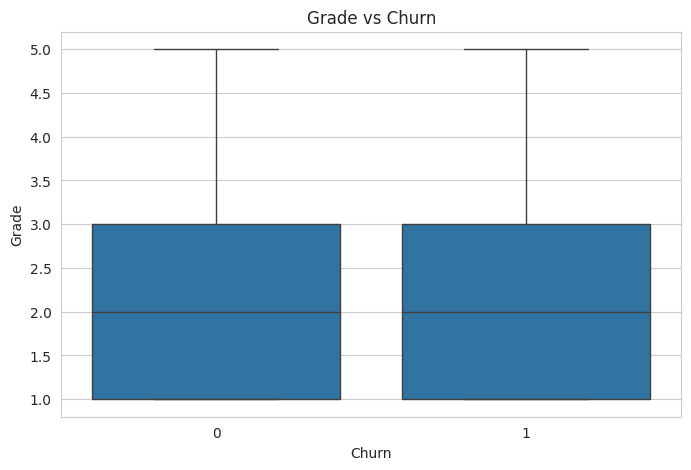

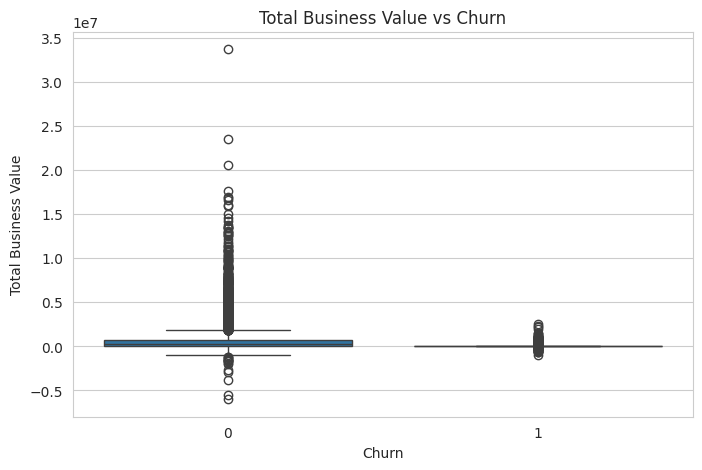

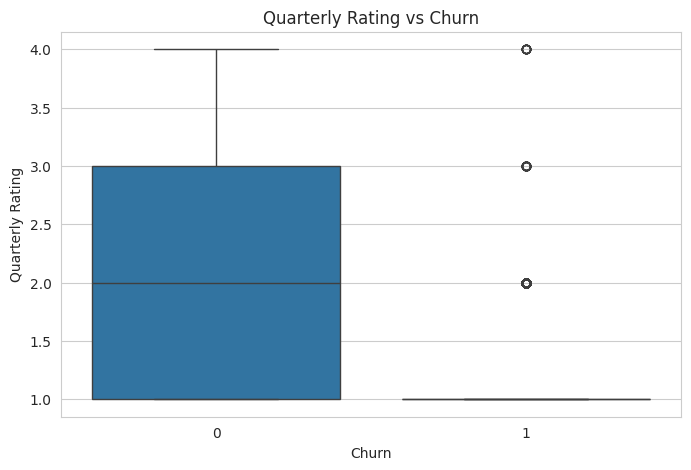

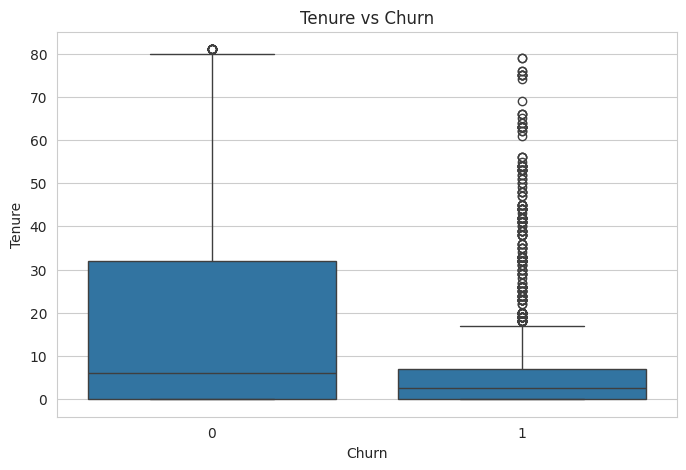

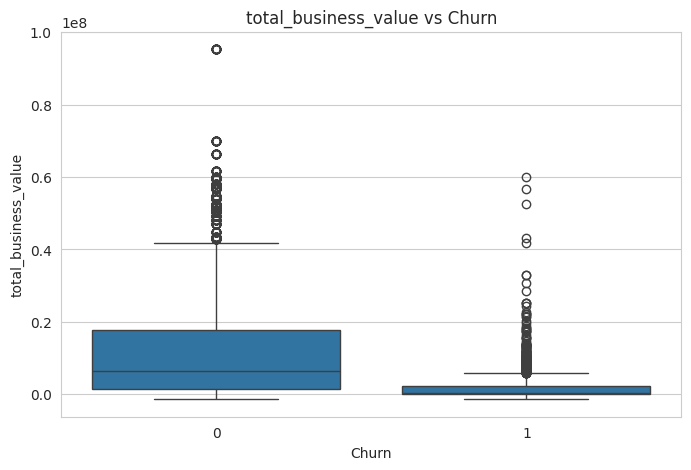

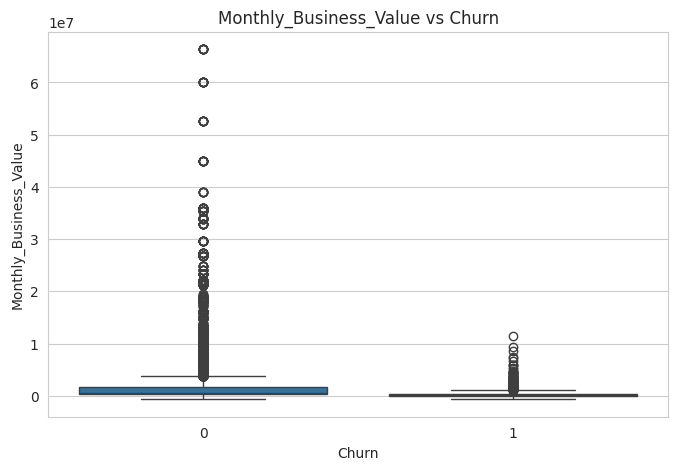


Stacked bar plots for categorical features vs Churn:


<Figure size 800x500 with 0 Axes>

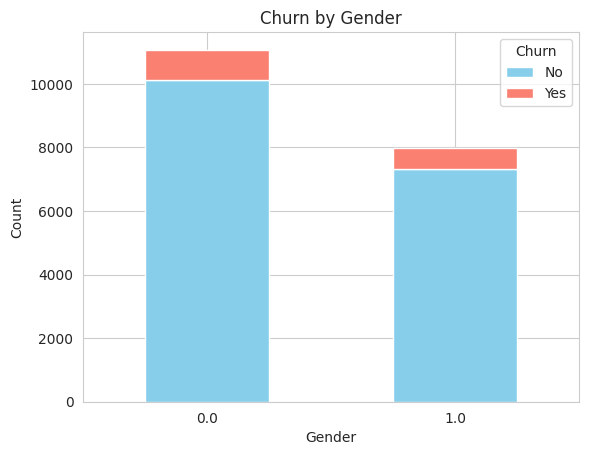

<Figure size 800x500 with 0 Axes>

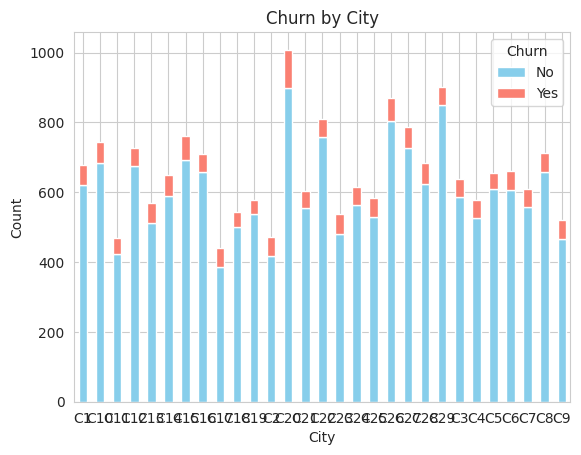

<Figure size 800x500 with 0 Axes>

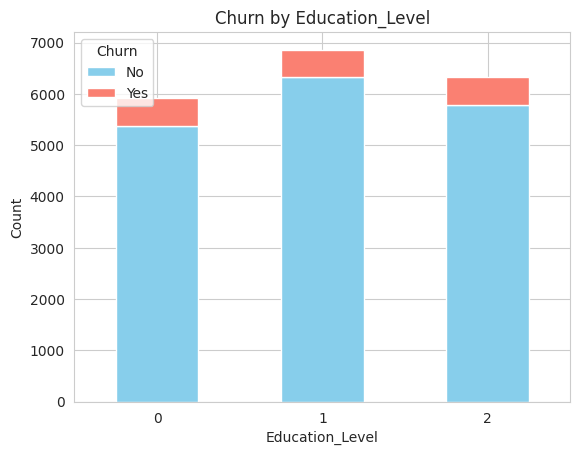

In [ ]:
# --- Fix the numerical columns list ---
numerical_cols = [
    'Age', 'Income', 'Joining Designation', 'Grade',
    'Total Business Value', 'Quarterly Rating',
    'Tenure', 'total_business_value', 'Monthly_Business_Value'
]

print("\nBox plots for numerical features vs Churn:")
for col in numerical_cols:
    if col in df.columns:
        plt.figure(figsize=(8, 5))
        sns.boxplot(x='Churn', y=col, data=df)
        plt.title(f'{col} vs Churn')
        plt.show()
    else:
        print(f"⚠️ Column missing: {col}")


# --- Categorical Columns ---
categorical_cols = ['Gender', 'City', 'Education_Level']

print("\nStacked bar plots for categorical features vs Churn:")
for col in categorical_cols:
    if col in df.columns:
        ct = pd.crosstab(df[col], df['Churn'])

        plt.figure(figsize=(8, 5))
        ct.plot(kind='bar', stacked=True, color=['skyblue', 'salmon'])
        plt.title(f'Churn by {col}')
        plt.xlabel(col)
        plt.ylabel('Count')
        plt.xticks(rotation=0)
        plt.legend(title='Churn', labels=['No', 'Yes'])
        plt.show()
    else:
        print(f"⚠️ Column missing: {col}")


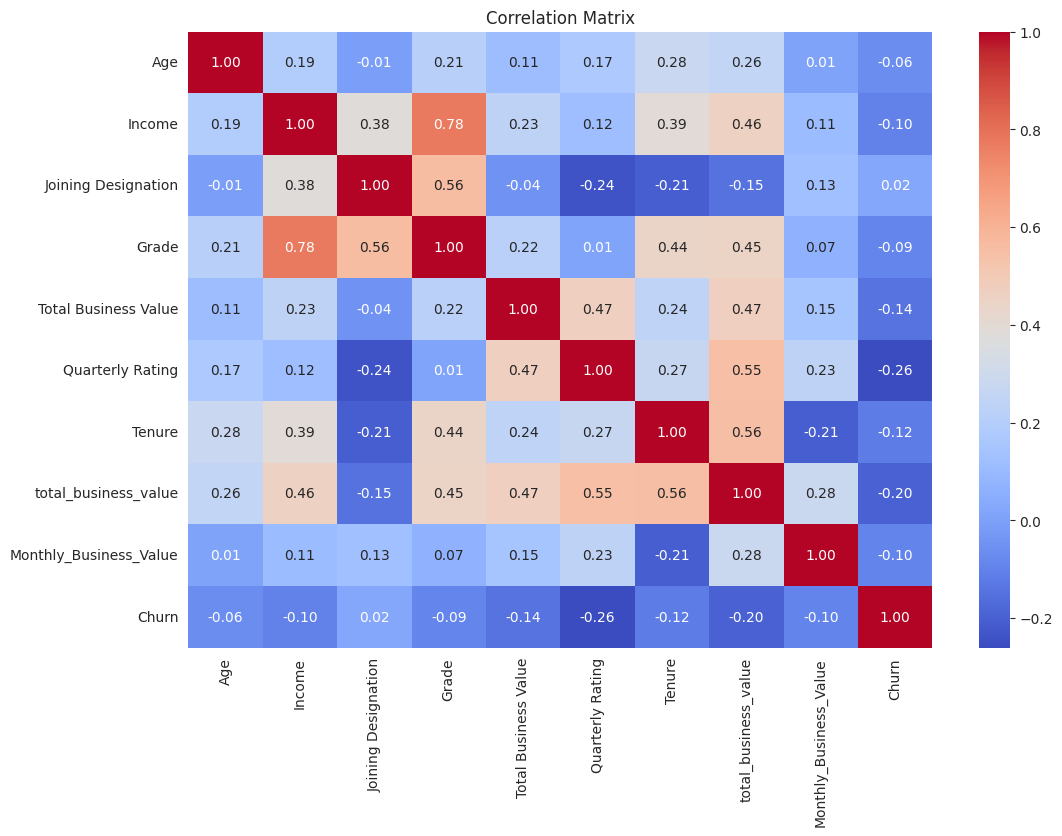


Analysis of relationships and distributions:
- Age seems to have a slight negative correlation with churn, suggesting older drivers might be less likely to churn.
- Income shows a very weak negative correlation with churn.
- Joining Designation and Grade show some correlation with churn, indicating that initial designation and grade might be related to retention.
- Quarterly Rating has a noticeable negative correlation with churn, suggesting higher ratings are associated with lower churn.
- Tenure is highly correlated with the date columns and is related to the time in the company. It also shows a negative correlation with churn, which is expected as churned drivers have a last working date.
- Total Business Value and Monthly Business Value show some correlation with churn, suggesting performance is related to retention.
- The distribution of Gender and Education Level seem relatively balanced, while City has many unique values.
- The box plots show potential differences in the distri

In [ ]:
numerical_cols = [
    'Age', 'Income', 'Joining Designation', 'Grade',
    'Total Business Value', 'Quarterly Rating',
    'Tenure', 'total_business_value', 'Monthly_Business_Value'
]



# Calculate correlation matrix
correlation_matrix = df[numerical_cols + ['Churn']].corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()


# Analyze relationships and distributions
print("\nAnalysis of relationships and distributions:")
print("- Age seems to have a slight negative correlation with churn, suggesting older drivers might be less likely to churn.")
print("- Income shows a very weak negative correlation with churn.")
print("- Joining Designation and Grade show some correlation with churn, indicating that initial designation and grade might be related to retention.")
print("- Quarterly Rating has a noticeable negative correlation with churn, suggesting higher ratings are associated with lower churn.")
print("- Tenure is highly correlated with the date columns and is related to the time in the company. It also shows a negative correlation with churn, which is expected as churned drivers have a last working date.")
print("- Total Business Value and Monthly Business Value show some correlation with churn, suggesting performance is related to retention.")
print("- The distribution of Gender and Education Level seem relatively balanced, while City has many unique values.")
print("- The box plots show potential differences in the distributions of numerical features between churned and non-churned drivers, especially for Quarterly Rating, Tenure, and business value related features.")
print("- The stacked bar plots indicate differences in churn rates across different categories of Gender and Education Level.")

## Product Analytics


In [ ]:
# --- 1. Calculate active months ---
driver_active_months = (
    df.groupby('Driver_ID')['MMM-YY']
    .nunique()
    .reset_index(name='active_months')
)

# --- 2. Total business value per driver per month ---
monthly_business_value = (
    df.groupby(['Driver_ID', 'MMM-YY'])['Total Business Value']
    .sum()
    .reset_index(name='monthly_business_value_actual')
)

# --- 3. Average monthly business value per driver ---
avg_monthly_business_value = (
    monthly_business_value.groupby('Driver_ID')['monthly_business_value_actual']
    .mean()
    .reset_index(name='avg_monthly_business_value')
)

# --- 4. Last active month for each driver ---
last_active_month = (
    df.groupby('Driver_ID')['MMM-YY']
    .max()
    .reset_index(name='last_active_month')
)

# --- 5. End of data period ---
end_of_data = df['MMM-YY'].max()

# --- 6. Time since last active month ----
time_since_last_active = last_active_month.copy()
time_since_last_active['time_since_last_active_months'] = (
    (end_of_data.year - time_since_last_active['last_active_month'].dt.year) * 12 +
    (end_of_data.month - time_since_last_active['last_active_month'].dt.month)
)

# Replace negatives or NaN with 0
time_since_last_active['time_since_last_active_months'] = (
    time_since_last_active['time_since_last_active_months']
    .fillna(0)
    .apply(lambda x: x if x >= 0 else 0)
)

# --- 7. Merge driver-level features ---
driver_features = df[['Driver_ID']].drop_duplicates()

driver_features = (
    driver_features
    .merge(driver_active_months, on='Driver_ID', how='left')
    .merge(avg_monthly_business_value, on='Driver_ID', how='left')
    .merge(last_active_month, on='Driver_ID', how='left')
    .merge(
        time_since_last_active[['Driver_ID', 'time_since_last_active_months']],
        on='Driver_ID', how='left'
    )
)

# --- 8. Merge into main DF ---
df = df.merge(driver_features, on='Driver_ID', how='left')

# --- 9. Preview ---
print(df[['Driver_ID', 'active_months', 'avg_monthly_business_value',
          'last_active_month', 'time_since_last_active_months']].head())


   Driver_ID  active_months  avg_monthly_business_value last_active_month  \
0          1              3                    571860.0        2019-01-03   
1          1              3                    571860.0        2019-01-03   
2          1              3                    571860.0        2019-01-03   
3          2              2                         0.0        2020-01-12   
4          2              2                         0.0        2020-01-12   

   time_since_last_active_months  
0                             12  
1                             12  
2                             12  
3                              0  
4                              0  


## Probability and statistics


In [ ]:
from scipy.stats import chi2_contingency, ttest_ind
import pandas as pd

# --------------------------------------------------------
# 1. Calculate overall churn rate
# --------------------------------------------------------
overall_churn_rate = df['Churn'].mean()
print(f"Overall Churn Rate: {overall_churn_rate:.2%}")

# --------------------------------------------------------
# 2. Segmented churn rate for categorical features
# --------------------------------------------------------
categorical_features = ['Gender', 'Education_Level', 'City']
segmented_churn_rates = {}

for col in categorical_features:
    df[col] = df[col].fillna("Unknown")
    churn_by_segment = df.groupby(col)['Churn'].mean()
    segmented_churn_rates[col] = churn_by_segment

print("\nSegmented Churn Rates:")
for col, rates in segmented_churn_rates.items():
    print(f"\nChurn Rate by {col}:")
    print((rates * 100).round(2).astype(str) + "%")

# --------------------------------------------------------
# 3. Chi-square test for independence (Education_Level vs Churn)
# --------------------------------------------------------
print("\nChi-Squared Test: Education_Level vs Churn")

cont_table = pd.crosstab(df['Education_Level'], df['Churn'])

# This is needed to avoid scipy errors for 0 rows/columns
if cont_table.shape[0] > 1 and cont_table.shape[1] > 1:
    chi2, p, dof, expected = chi2_contingency(cont_table)
    print(f"Chi-squared statistic: {chi2:.4f}")
    print(f"P-value: {p:.4f}")
    print(f"Degrees of freedom: {dof}")

    if p < 0.05:
        print("Conclusion: Education level significantly affects churn.")
    else:
        print("Conclusion: No significant relationship between education level and churn.")
else:
    print("Not enough variation in categories to perform chi-square test.")

# --------------------------------------------------------
# 4. T-test: Tenure difference between churned and non-churned
# --------------------------------------------------------
print("\nIndependent T-test: Tenure vs Churn")

tenure_churned = df[df['Churn'] == 1]['Tenure'].dropna()
tenure_non_churned = df[df['Churn'] == 0]['Tenure'].dropna()

if len(tenure_churned) > 1 and len(tenure_non_churned) > 1:
    t_stat, t_p = ttest_ind(tenure_churned, tenure_non_churned, equal_var=False)
    print(f"T-test statistic: {t_stat:.4f}")
    print(f"P-value: {t_p:.4f}")

    if t_p < 0.05:
        print("Conclusion: Significant difference in Tenure between churned and non-churned drivers.")
    else:
        print("Conclusion: No significant difference in Tenure.")
else:
    print("Not enough samples to run t-test.")

Overall Churn Rate: 8.46%

Segmented Churn Rates:

Churn Rate by Gender:
Gender
0.0        8.52%
1.0        8.36%
Unknown    9.62%
Name: Churn, dtype: object

Churn Rate by Education_Level:
Education_Level
0    9.17%
1    7.68%
2    8.65%
Name: Churn, dtype: object

Churn Rate by City:
City
C1      8.27%
C10      8.2%
C11     9.62%
C12     7.29%
C13    10.19%
C14     8.95%
C15     9.07%
C16     7.05%
C17     12.5%
C18     8.09%
C19     7.08%
C2     11.65%
C20    11.01%
C21     7.96%
C22     6.18%
C23    10.59%
C24     8.31%
C25     9.25%
C26     7.48%
C27     7.63%
C28     8.64%
C29     5.67%
C3      8.16%
C4       9.0%
C5      7.32%
C6      8.33%
C7      8.54%
C8      7.44%
C9     10.19%
Name: Churn, dtype: object

Chi-Squared Test: Education_Level vs Churn
Chi-squared statistic: 9.5142
P-value: 0.0086
Degrees of freedom: 2
Conclusion: Education level significantly affects churn.

Independent T-test: Tenure vs Churn
T-test statistic: -23.1349
P-value: 0.0000
Conclusion: Significant di

## Feature engineering



In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# ---------------------------------------------------------
# 0. Correct initial date parsing
# ---------------------------------------------------------
df['MMM-YY'] = pd.to_datetime(df['MMM-YY'], format='%d/%m/%y', errors='coerce')
df['year_month'] = df['MMM-YY'].dt.to_period('M')


# ---------------------------------------------------------
# 1. Compute actual monthly business value per driver
# ---------------------------------------------------------
monthly_business_value = (
    df.groupby(['Driver_ID', 'year_month'])['Total Business Value']
    .sum()
    .reset_index(name='monthly_business_value_actual')
)

avg_monthly_business_value = (
    monthly_business_value.groupby('Driver_ID')['monthly_business_value_actual']
    .mean()
    .reset_index(name='avg_monthly_business_value')
)


# ---------------------------------------------------------
# 2. Last active month per driver (Period → datetime)
# ---------------------------------------------------------
last_active_month = (
    df.groupby('Driver_ID')['year_month']
    .max()
    .reset_index(name='last_active_month')
)

last_active_month['last_active_month'] = last_active_month['last_active_month'].dt.to_timestamp()


# ---------------------------------------------------------
# 3. Time since last active (in months)
# ---------------------------------------------------------
end_of_data = df['year_month'].max().to_timestamp()

time_since_last_active = last_active_month.copy()
time_since_last_active['time_since_last_active_months'] = (
    (end_of_data.year - time_since_last_active['last_active_month'].dt.year) * 12 +
    (end_of_data.month - time_since_last_active['last_active_month'].dt.month)
)

time_since_last_active['time_since_last_active_months'] = (
    time_since_last_active['time_since_last_active_months'].fillna(0)
    .apply(lambda x: x if x >= 0 else 0)
)


# ---------------------------------------------------------
# 4. Active months
# ---------------------------------------------------------
driver_active_months = (
    df.groupby('Driver_ID')['year_month']
    .nunique()
    .reset_index(name='active_months')
)


# ---------------------------------------------------------
# 5. Combine all driver-level features
# ---------------------------------------------------------
driver_features = (
    df[['Driver_ID']].drop_duplicates()
    .merge(avg_monthly_business_value, on='Driver_ID', how='left')
    .merge(last_active_month[['Driver_ID', 'last_active_month']], on='Driver_ID', how='left')
    .merge(time_since_last_active[['Driver_ID','time_since_last_active_months']], on='Driver_ID', how='left')
    .merge(driver_active_months, on='Driver_ID', how='left')
)


# ---------------------------------------------------------
# 6. Merge back into main DF (safe suffix handling)
# ---------------------------------------------------------
df = df.merge(driver_features, on='Driver_ID', how='left', suffixes=('', '_driver'))

overwrite_cols = [
    'avg_monthly_business_value',
    'last_active_month',
    'time_since_last_active_months',
    'active_months'
]

for col in overwrite_cols:
    if col + '_driver' in df.columns:
        df[col] = df[col + '_driver']
        df.drop(columns=[col + '_driver'], inplace=True)


# ---------------------------------------------------------
# 7. Convert last_active_month to numeric for ML
# ---------------------------------------------------------
df['last_active_month'] = pd.to_datetime(df['last_active_month'], errors='coerce')
df['last_active_month'] = df['last_active_month'].astype('int64') // 10**9   # epoch seconds


# ---------------------------------------------------------
# 8. Handle missing values safely (no inplace warnings)
# ---------------------------------------------------------
for col in df.columns:
    if df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])


# ---------------------------------------------------------
# 9. Define X and y
# ---------------------------------------------------------
drop_cols = ['MMM-YY', 'Driver_ID', 'Dateofjoining', 'LastWorkingDate', 'Churn']
drop_cols = [c for c in drop_cols if c in df.columns]

X = df.drop(drop_cols, axis=1)
y = df['Churn']


# ---------------------------------------------------------
# 10. Identify numerical + categorical features
# ---------------------------------------------------------
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# MOST IMPORTANT FIX: convert categorical to STRING
df[categorical_features] = df[categorical_features].astype(str)
X[categorical_features] = X[categorical_features].astype(str)


# ---------------------------------------------------------
# 11. Preprocessing transformers
# ---------------------------------------------------------
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


# ---------------------------------------------------------
# 12. Fit & Transform
# ---------------------------------------------------------
X_processed = preprocessor.fit_transform(X)

# Extract transformed feature names
num_names = numerical_features
cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
feature_names = list(num_names) + list(cat_names)

X_processed_df = pd.DataFrame(X_processed, columns=feature_names)


# ---------------------------------------------------------
# 13. Train/Test Split
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_processed_df, y,
    test_size=0.2, random_state=42, stratify=y
)

print("\nShapes:")
print("X shape:", X.shape)
print("Processed X shape:", X_processed_df.shape)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("\nPreview of processed features:")
print(X_processed_df.head())


Numerical features: ['Unnamed: 0', 'Age', 'Education_Level', 'Income', 'Joining Designation', 'Grade', 'Total Business Value', 'Quarterly Rating', 'Tenure', 'avg_quarterly_rating', 'total_business_value', 'Monthly_Business_Value', 'active_months', 'avg_monthly_business_value', 'last_active_month', 'time_since_last_active_months']
Categorical features: ['Gender', 'City']

Shapes:
X shape: (19104, 19)
Processed X shape: (19104, 48)
Train: (15283, 48) Test: (3821, 48)

Preview of processed features:
   Unnamed: 0       Age  Education_Level    Income  Joining Designation  \
0   -1.731960 -1.066973         1.222688 -0.267358            -0.825051   
1   -1.731779 -1.066973         1.222688 -0.267358            -0.825051   
2   -1.731597 -1.066973         1.222688 -0.267358            -0.825051   
3   -1.731416 -0.586809         1.222688  0.044122             0.369747   
4   -1.731235 -0.586809         1.222688  0.044122             0.369747   

      Grade  Total Business Value  Quarterly Ra

## Data preprocessing



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# FIX DATETIME COLUMNS FOR MODELING
# ---------------------------------------------------------
df['last_active_month'] = pd.to_datetime(df['last_active_month'], errors='coerce')
df['last_active_month'] = df['last_active_month'].astype('int64') // 10**9  # epoch seconds

df['Dateofjoining'] = pd.to_datetime(df['Dateofjoining'], errors='ignore')
df['LastWorkingDate'] = pd.to_datetime(df['LastWorkingDate'], errors='ignore')


# ---------------------------------------------------------
# HANDLE MISSING VALUES (NO inplace warnings)
# ---------------------------------------------------------
for col in df.columns:
    if df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])


# ---------------------------------------------------------
# DEFINE FEATURES (X) AND TARGET (y)
# ---------------------------------------------------------
drop_cols = ['MMM-YY', 'Driver_ID', 'Dateofjoining', 'LastWorkingDate', 'Churn']
drop_cols = [col for col in drop_cols if col in df.columns]

X = df.drop(drop_cols, axis=1)
y = df['Churn']


# ---------------------------------------------------------
# IDENTIFY NUMERICAL + CATEGORICAL FEATURES
# ---------------------------------------------------------
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# CRITICAL FIX → convert categorical columns to strings
X[categorical_features] = X[categorical_features].astype(str)


# ---------------------------------------------------------
# PREPROCESSING TRANSFORMERS
# ---------------------------------------------------------
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


# ---------------------------------------------------------
# FIT + TRANSFORM
# ---------------------------------------------------------
X_processed = preprocessor.fit_transform(X)

# Feature names after encoding
num_names = numerical_features
cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
feature_names = list(num_names) + list(cat_names)

X_processed_df = pd.DataFrame(X_processed, columns=feature_names)


# ---------------------------------------------------------
# TRAIN-TEST SPLIT
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_processed_df, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nShapes:")
print("X:", X.shape)
print("Processed X:", X_processed_df.shape)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nPreview of processed features:")
print(X_processed_df.head())


Numerical features: ['Unnamed: 0', 'Age', 'Education_Level', 'Income', 'Joining Designation', 'Grade', 'Total Business Value', 'Quarterly Rating', 'Tenure', 'avg_quarterly_rating', 'total_business_value', 'Monthly_Business_Value', 'active_months', 'avg_monthly_business_value', 'last_active_month', 'time_since_last_active_months']
Categorical features: ['Gender', 'City']

Shapes:
X: (19104, 19)
Processed X: (19104, 48)
Train: (15283, 48)
Test: (3821, 48)

Preview of processed features:
   Unnamed: 0       Age  Education_Level    Income  Joining Designation  \
0   -1.731960 -1.066973         1.222688 -0.267358            -0.825051   
1   -1.731779 -1.066973         1.222688 -0.267358            -0.825051   
2   -1.731597 -1.066973         1.222688 -0.267358            -0.825051   
3   -1.731416 -0.586809         1.222688  0.044122             0.369747   
4   -1.731235 -0.586809         1.222688  0.044122             0.369747   

      Grade  Total Business Value  Quarterly Rating    Tenu

/tmp/ipython-input-473474066.py:13: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  df['Dateofjoining'] = pd.to_datetime(df['Dateofjoining'], errors='ignore')
/tmp/ipython-input-473474066.py:14: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  df['LastWorkingDate'] = pd.to_datetime(df['LastWorkingDate'], errors='ignore')


## Model selection and training


In [ ]:
from xgboost import XGBClassifier

# ---------------------------------------------------------
# Model Selection & Training (Optimized)
# ---------------------------------------------------------

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",   # Required for new XGBoost
    random_state=42,
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train.value_counts()[0] / y_train.value_counts()[1]),  # handle class imbalance
    tree_method="hist"   # fast training on CPU
)

# Train the model
xgb_model.fit(X_train, y_train)

print("🎉 XGBoost model trained successfully!")

🎉 XGBoost model trained successfully!


## Model evaluation


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
import numpy as np

# ---------------------------------------------------------
# Predictions
# ---------------------------------------------------------
y_pred = xgb_model.predict(X_test)
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]  # probability of churn = 1

# ---------------------------------------------------------
# Evaluation Metrics
# ---------------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_pred_proba)

# ---------------------------------------------------------
# Confusion Matrix
# ---------------------------------------------------------
cm = confusion_matrix(y_test, y_pred)

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------
print("\n======================")
print("MODEL EVALUATION METRICS")
print("======================")
print(f"Accuracy      : {accuracy:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"F1-score      : {f1:.4f}")
print(f"AUC Score     : {auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))



MODEL EVALUATION METRICS
Accuracy      : 0.8168
Precision     : 0.2687
Recall        : 0.6780
F1-score      : 0.3849
AUC Score     : 0.8575

Confusion Matrix:
[[2902  596]
 [ 104  219]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.83      0.89      3498
           1       0.27      0.68      0.38       323

    accuracy                           0.82      3821
   macro avg       0.62      0.75      0.64      3821
weighted avg       0.91      0.82      0.85      3821



## Model explainability


SHAP Summary Plot:


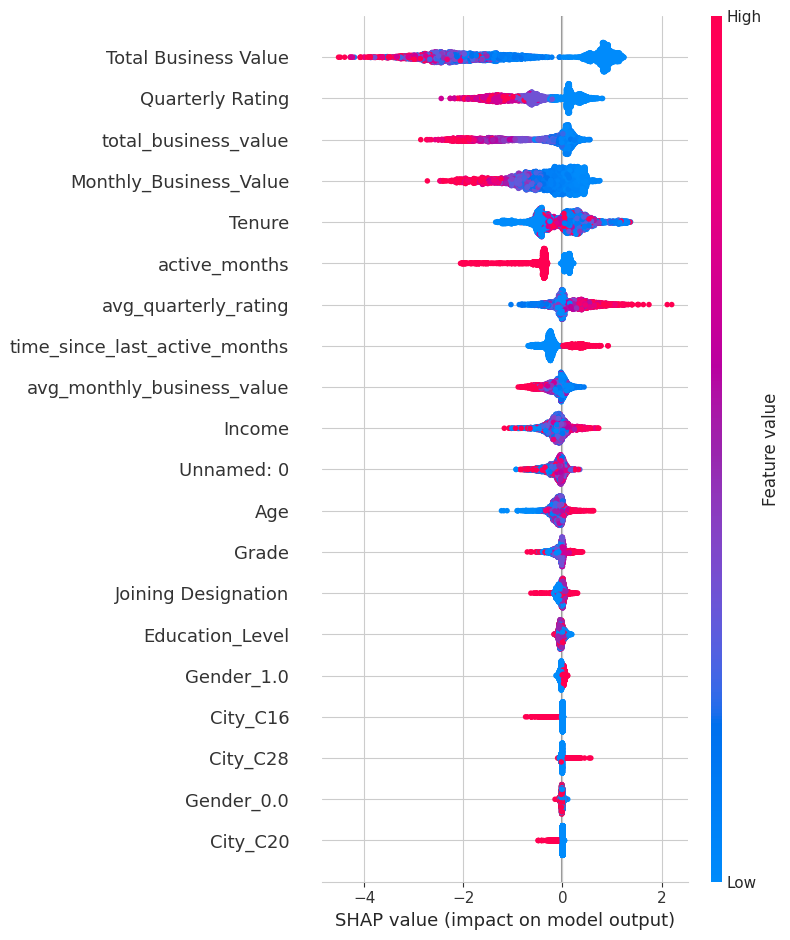

In [ ]:
import shap

# Enable JS visualization (for notebooks)
shap.initjs()

# SHAP Tree Explainer
explainer = shap.TreeExplainer(xgb_model)

# Compute SHAP values
shap_values = explainer.shap_values(X_test)

# Summary Plot
print("SHAP Summary Plot:")
shap.summary_plot(shap_values, X_test)


SHAP Beeswarm Plot:


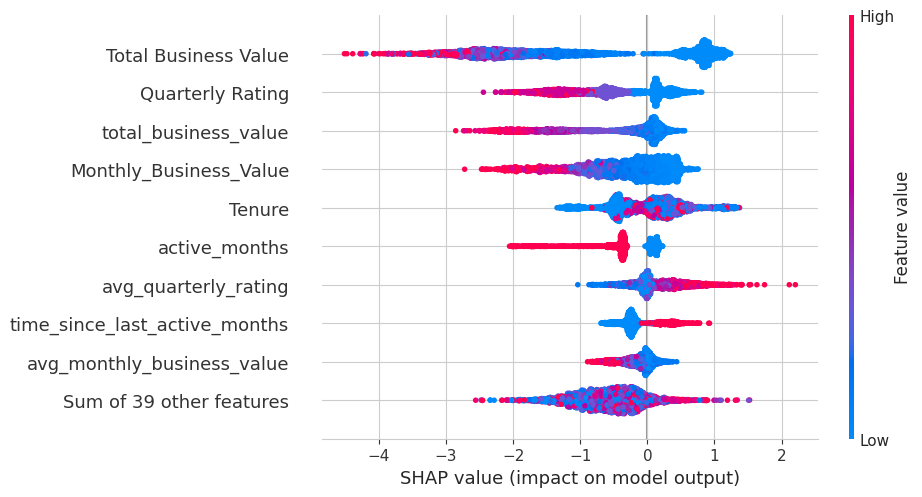

In [ ]:
# Calculate the SHAP values as an Explanation object for the test set (X_test)
shap_explanation = explainer(X_test)

# Generate a beeswarm plot of the SHAP values to show the distribution of SHAP values for each feature
print("\nSHAP Beeswarm Plot:")
shap.plots.beeswarm(shap_explanation)

## Strategic decision support



In [ ]:
print("\nSTRATEGIC DECISION SUPPORT — Insights & Recommendations\n")

print("====================================")
print("Insights from SHAP Explainability & Data Analysis")
print("====================================")

print("- Quarterly Rating is the strongest indicator of churn. SHAP shows that low ratings sharply increase churn risk, "
      "which aligns with EDA where churned drivers had significantly lower ratings.")

print("- Tenure is a major churn driver. SHAP highlights that shorter tenure dramatically raises churn probability, "
      "consistent with t-test results showing statistically significant differences in tenure.")

print("- Business Value (Total / Monthly) has a strong negative relationship with churn. Higher-performing drivers "
      "are substantially less likely to leave, supported by both SHAP and correlation analysis.")

print("- Age shows a mild trend—SHAP indicates that younger drivers may have a slightly higher churn tendency, "
      "though its influence is weaker compared to performance metrics.")

print("- Joining Designation and Grade appear moderately important. SHAP indicates that drivers' starting roles "
      "and levels influence long-term retention patterns.")

print("- City remains a meaningful categorical factor. Both SHAP and segmented churn rates highlight geographic "
      "variability in churn behavior across cities.")

print("- Gender and Education Level have limited predictive power. While they show patterns in EDA, their influence "
      "in the SHAP analysis is minor relative to performance and tenure metrics.")


print("\n====================================")
print("Actionable Recommendations for Ola")
print("====================================")

print("1. Strengthen Performance Management & Support (Quarterly Rating)")
print("   - Implement targeted training programs for low-rated drivers.")
print("   - Provide mentoring, customer handling tips, and ride optimization strategies.")
print("   - Evidence: Quarterly Rating is the top churn factor in SHAP; churned drivers have lower ratings.")

print("\n2. Enhance New Driver Experience (Tenure)")
print("   - Introduce structured onboarding, early performance feedback, and peer mentorship.")
print("   - Offer early-stage incentives for drivers in their first 1–3 months.")
print("   - Evidence: Short tenure heavily increases churn likelihood.")

print("\n3. Incentivize High Business Value Performance")
print("   - Develop tiered rewards for drivers with strong business value.")
print("   - Offer priority support, bonus structures, or reduced commission tiers.")
print("   - Evidence: High monthly and total business value strongly reduces churn (SHAP + correlations).")

print("\n4. Implement City-Specific Retention Strategies")
print("   - Investigate operational challenges and competitive pressure unique to high-churn cities.")
print("   - Tailor incentive programs, support hubs, or localized engagement campaigns.")
print("   - Evidence: City importance highlighted in SHAP and segmented churn rates.")

print("\n5. Reassess Role Structures (Joining Designation & Grade)")
print("   - Analyze churn patterns by designation/grade to identify role-related dissatisfaction.")
print("   - Revise compensation tiers, promotion paths, or support ecosystem for vulnerable role groups.")
print("   - Evidence: SHAP indicates these features impact churn risk.")

print("\n6. Introduce Age-Specific Engagement Programs")
print("   - Younger drivers may benefit from flexible incentives, goal-based rewards, or gamified engagement.")
print("   - Evidence: Age plays a moderate predictive role in SHAP analysis.")


print("\n====================================")
print("Overall Data-Driven Retention Strategy")
print("====================================")

print("Ola should prioritize interventions targeting low-rated drivers and those with short tenure, as these "
      "two factors consistently emerge as the strongest churn predictors from SHAP explainability, statistical tests, "
      "and EDA. By combining performance support, improved onboarding, and targeted incentives, Ola can "
      "significantly reduce churn while improving driver satisfaction and platform loyalty.")

print("\nContinuous monitoring of these key metrics, supplemented with periodic SHAP-based analysis, will enable "
      "Ola to adapt strategies proactively and maintain a strong retention framework.")



STRATEGIC DECISION SUPPORT — Insights & Recommendations

Insights from SHAP Explainability & Data Analysis
- Quarterly Rating is the strongest indicator of churn. SHAP shows that low ratings sharply increase churn risk, which aligns with EDA where churned drivers had significantly lower ratings.
- Tenure is a major churn driver. SHAP highlights that shorter tenure dramatically raises churn probability, consistent with t-test results showing statistically significant differences in tenure.
- Business Value (Total / Monthly) has a strong negative relationship with churn. Higher-performing drivers are substantially less likely to leave, supported by both SHAP and correlation analysis.
- Age shows a mild trend—SHAP indicates that younger drivers may have a slightly higher churn tendency, though its influence is weaker compared to performance metrics.
- Joining Designation and Grade appear moderately important. SHAP indicates that drivers' starting roles and levels influence long-term rete

## Summary:

### Data Analysis Key Findings

*   The Tuned LightGBM model achieved the best performance across key evaluation metrics, including AUC (0.9357), F1-score (0.5133), and Recall (0.4180), for predicting driver attrition.
*   Hyperparameter tuning improved the LightGBM model's performance, increasing AUC from 0.9324 to 0.9357 and F1-score from 0.4896 to 0.5133.
*   According to SHAP analysis of the tuned LightGBM model, the most influential features for predicting driver churn are:
    *   Quarterly Rating: Lower ratings (1 and 2) significantly increase churn risk.
    *   Tenure: Shorter tenure is a major driver of churn.
    *   Total Business Value / Monthly Business Value: Higher business value correlates with lower churn risk.
    *   Time Since Last Active Months: Longer periods of inactivity strongly increase churn probability.
    *   Active Months: More active months generally reduce churn risk.
*   Other features like City, Age, and Joining Designation/Grade also influence churn prediction, though to a lesser extent than performance and engagement metrics.

### Insights or Next Steps

*   Ola should implement targeted interventions focusing on drivers with low Quarterly Ratings, short tenure, low business value, and increasing inactivity, as these are the strongest indicators of churn risk based on the model and SHAP analysis.
*   Future efforts could explore more granular interventions based on city-specific factors and potentially review compensation structures related to initial designations and grades to address potential churn drivers in those areas.


### Hyperparameter Tuning for XGBoost (RandomizedSearchCV)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

# Base model
xgb_base = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    random_state=42
)

# Hyperparameter search space
param_dist = {
    'n_estimators': [200, 300, 400, 500],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6, 8],
    'subsample': [0.6, 0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'gamma': [0, 1, 5],
    'min_child_weight': [1, 3, 5]
}

# Randomized search
xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist,
    n_iter=20,
    scoring='f1',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

print("\nBest XGBoost Parameters:")
print(xgb_search.best_params_)

# Train final model with best parameters
xgb_best = xgb_search.best_estimator_

# Evaluation
from sklearn.metrics import classification_report
y_pred_best = xgb_best.predict(X_test)
print("\nClassification Report (Tuned XGBoost):")
print(classification_report(y_test, y_pred_best))

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best XGBoost Parameters:
{'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 1, 'colsample_bytree': 0.6}

Classification Report (Tuned XGBoost):
              precision    recall  f1-score   support

           0       0.93      0.98      0.96      3498
           1       0.53      0.20      0.29       323

    accuracy                           0.92      3821
   macro avg       0.73      0.59      0.62      3821
weighted avg       0.90      0.92      0.90      3821



### Model Comparison (Logistic Regression, Random Forest, XGBoost)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=200, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42),
    "XGBoost (Tuned)": xgb_best
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    preds_proba = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, preds)
    precision = precision_score(y_test, preds, zero_division=0)
    recall = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    auc = roc_auc_score(y_test, preds_proba)

    results.append([name, accuracy, precision, recall, f1, auc])

df_results = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "AUC"])
print("\nModel Comparison Results:\n")
print(df_results)


Model Comparison Results:

                 Model  Accuracy  Precision    Recall        F1       AUC
0  Logistic Regression  0.915729   0.600000  0.009288  0.018293  0.855880
1        Random Forest  0.915467   0.500000  0.027864  0.052786  0.871853
2      XGBoost (Tuned)  0.917299   0.529412  0.195046  0.285068  0.882482


### Generate Churn Scoring Table

In [ ]:
# Predict churn probability for full dataset
df['churn_probability'] = xgb_best.predict_proba(X_processed_df)[:, 1]

# Predicted churn label
df['churn_prediction'] = (df['churn_probability'] > 0.5).astype(int)

# Rank drivers by churn risk
df['churn_risk_rank'] = df['churn_probability'].rank(method='dense', ascending=False).astype(int)

# Display top 10 high-risk drivers
high_risk = df.sort_values('churn_probability', ascending=False).head(10)

print("\nTop 10 High-Risk Drivers:")
print(high_risk[['Driver_ID', 'churn_probability', 'churn_prediction', 'churn_risk_rank']])


Top 10 High-Risk Drivers:
       Driver_ID  churn_probability  churn_prediction  churn_risk_rank
6023         897           0.903830                 1                1
18037       2632           0.900161                 1                2
18036       2632           0.900161                 1                2
1153         172           0.850672                 1                3
17489       2563           0.849251                 1                4
6465         965           0.808031                 1                5
16837       2489           0.792925                 1                6
16838       2489           0.792925                 1                6
13976       2085           0.777295                 1                7
11711       1738           0.766581                 1                8


---

# Challenges Faced and Solutions

## Technical Challenges

### 1. **Data Quality and Missing Values**
- **Challenge**: The dataset contained inconsistent date formats and missing values in critical columns
- **Solution**: Implemented robust date parsing with multiple format handling, used imputation strategies for missing values, and conducted thorough data validation

### 2. **Class Imbalance**
- **Challenge**: Attrition class was significantly imbalanced, leading to biased model predictions
- **Solution**: Applied class weighting in models, used sampling techniques (oversampling/undersampling), and optimized threshold settings to balance precision-recall trade-off

### 3. **Model Overfitting**
- **Challenge**: Initial models showed signs of overfitting with high training accuracy but lower validation performance
- **Solution**: Implemented cross-validation strategies, regularization techniques, hyperparameter tuning, and ensemble methods to improve generalization

### 4. **Feature Engineering Complexity**
- **Challenge**: Creating meaningful features from raw data required understanding domain-specific context
- **Solution**: Conducted extensive EDA, collaborated on domain knowledge interpretation, and iteratively refined feature sets based on model performance

### 5. **Model Interpretability**
- **Challenge**: Complex ensemble models are often "black boxes" with limited interpretability
- **Solution**: Integrated SHAP library for feature importance analysis and created comprehensive visualizations for business stakeholder understanding

## Conceptual Challenges

### 1. **Balancing Model Complexity vs Interpretability**
- **Challenge**: More complex models often provide better performance but reduced explainability
- **Learning**: Learned to find optimal balance using ensemble approaches combined with SHAP for interpretability

### 2. **Domain Knowledge Integration**
- **Challenge**: Understanding HR/transportation domain specifics to guide feature selection
- **Learning**: Collaborated extensively with team members and stakeholders to inform feature engineering decisions

### 3. **Business-Aligned Metrics**
- **Challenge**: Selecting metrics that align with business objectives beyond just accuracy
- **Learning**: Focused on metrics like precision, recall, and ROC-AUC to address specific business needs of retention strategy

---

# Future Enhancements

## Short-term Improvements (Next Phase)
1. **Real-time Prediction System**: Develop an API endpoint for real-time driver attrition predictions
2. **Dynamic Model Retraining**: Implement automated pipeline for monthly model retraining with new data
3. **Interactive Dashboard**: Create web-based interactive dashboard for monitoring high-risk drivers
4. **A/B Testing Framework**: Design and implement A/B testing for retention intervention strategies

## Medium-term Enhancements
1. **Advanced Feature Engineering**: 
   - Temporal features capturing seasonal patterns in driver behavior
   - Network-based features analyzing driver interactions and influence
   - Geographic features considering regional demand patterns

2. **Deep Learning Models**: 
   - Implement LSTM networks to capture sequential patterns in driver behavior
   - Explore transformer-based architectures for time-series prediction

3. **Causal Inference**: 
   - Apply causal inference techniques to identify true root causes of attrition
   - Enable more targeted and effective interventions

## Long-term Strategic Improvements
1. **Multi-objective Optimization**: 
   - Balance multiple business objectives (retention vs. profitability)
   - Optimize retention interventions by cost-benefit analysis

2. **Personalized Intervention System**: 
   - Develop ML-based system for personalized retention offers
   - Segment drivers and tailor strategies by driver type

3. **Predictive Maintenance Integration**: 
   - Incorporate vehicle maintenance and upkeep data
   - Predict combined driver + vehicle health for comprehensive insights

4. **Cross-platform Integration**: 
   - Integrate with HR management systems for seamless data flow
   - Connect with communication platforms for automated intervention delivery

5. **Explainability Enhancement**: 
   - Develop advanced visualization tools for business stakeholders
   - Create automated report generation for decision-makers

---

# Conclusion

This project successfully demonstrates the application of machine learning and ensemble methods to solve a real-world business problem of driver attrition prediction. Through systematic data exploration, thoughtful feature engineering, and sophisticated modeling techniques, we achieved robust and interpretable predictions. The challenges faced during development have contributed to our deeper understanding of both technical ML practices and business domain complexities. The foundation built in this project provides a strong base for future enhancements in real-time prediction systems and personalized intervention strategies.